# 24 · Field polygons, confidence and selection bias

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** map real FTW polygons; query their attributes; distinguish class probability from regional confidence.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=24_ftw_fields_confidence.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Move from pixels to predicted field units

We selected all provider polygons that intersect the raster window. Their geometries are **not clipped**;
the map viewport hides portions outside the window. `metrics:area` and `metrics:perimeter` describe the
provider's full polygons, in square metres and metres. We retain an edge-crossing flag so those areas cannot
silently be presented as area within this window. Selection is by intersection, not a random field sample.

The catalog describes polygons derived from thresholded field interiors. Their separate delivery and processing
mean a local contour of this probability array is not guaranteed to reproduce the published polygons exactly.

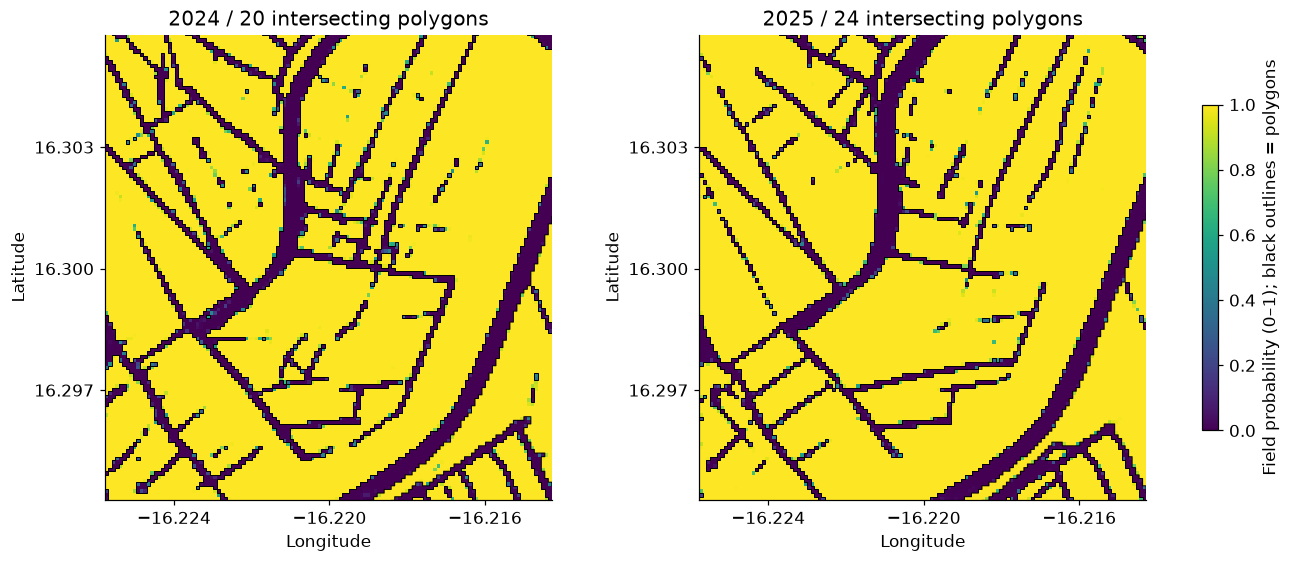

year, polygons, edge-crossing, with confidence, mean confidence: (2024, 20, 15, 20, 78.74001502990723)
year, polygons, edge-crossing, with confidence, mean confidence: (2025, 24, 19, 24, 73.62764517466228)


In [2]:
from ftw import load_ftw, raster_map, draw_fields, field_connection, export_fields
d=load_ftw('senegal')
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for t,ax in enumerate(axes):
    image=raster_map(ax,d,d['probability'][t,1],str(d['years'][t]))
    n=draw_fields(ax,d,d['years'][t])
    ax.set_title(f"{d['years'][t]} / {n} intersecting polygons")
fig.colorbar(image,ax=axes,label='Field probability (0–1); black outlines = polygons',shrink=.7)
plt.show()
con=field_connection(d)
for row in con.execute('SELECT year, COUNT(*), SUM(crosses_window_edge), COUNT(confidence), AVG(confidence) FROM fields GROUP BY year ORDER BY year'):
    print('year, polygons, edge-crossing, with confidence, mean confidence:',row)

## 2. Two scores with different spatial support

The field-interior probability belongs to a ~10 m pixel and is one of three softmax classes.
The polygon `confidence` attribute comes from a **separate 500 m confidence raster**, sampled upstream at
the polygon's representative point (a point on its surface). It is scaled as `raw / 0.578178 × 100`, capped at 100.
It is **not** the mean pixel probability and **not** the probability that every boundary vertex is correct.
Neighboring fields may share the same confidence cell.

The upstream guidance discusses a score around **69** as a possible quality filter. Treat it as a sensitivity
experiment: conservative scores outside the training distribution can remove real fields, particularly in
smallholder landscapes. Missing confidence is unknown, not zero.

year | minimum confidence | retained | sum of full polygon areas (ha)
2024 0 20 396.26
2024 30 20 396.26
2024 50 20 396.26
2024 69 12 92.23
2024 80 11 87.3
2024 90 7 59.08
2025 0 24 454.36
2025 30 24 454.36
2025 50 23 266.58
2025 69 16 92.31
2025 80 11 87.94
2025 90 2 19.04


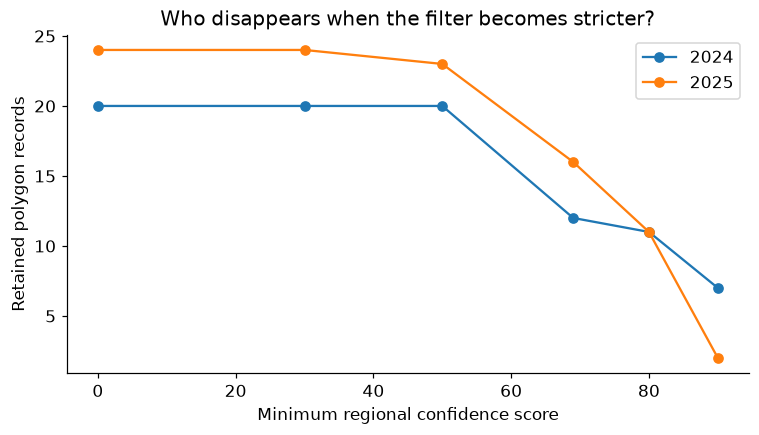

In [3]:
thresholds=[0,30,50,69,80,90]
print('year | minimum confidence | retained | sum of full polygon areas (ha)')
fig,ax=plt.subplots(figsize=(8,4))
for year in d['years']:
    retained=[]
    for cutoff in thresholds:
        n,area=con.execute('SELECT COUNT(*), COALESCE(SUM(area_m2),0)/10000 FROM fields WHERE year=? AND confidence>=?',(year,cutoff)).fetchone()
        retained.append(n)
        print(year,cutoff,n,round(area,2))
    ax.plot(thresholds,retained,marker='o',label=str(year))
ax.set(xlabel='Minimum regional confidence score',ylabel='Retained polygon records',title='Who disappears when the filter becomes stricter?')
ax.legend();plt.show()

## 3. Inspect the polygons that survive

For a simple full-polygon size distribution, restrict to polygons wholly inside the window. This avoids
using outside area but introduces an additional size-selection bias: large fields are more likely to cross
an edge. Do not present this as the country-wide field-size distribution. Counts and area sums from
different annual layers are not longitudinal tracking of the same fields.

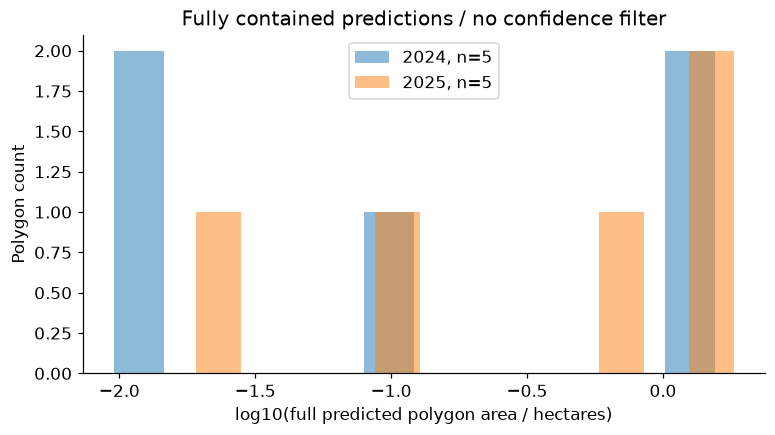

Outlined polygons: 16


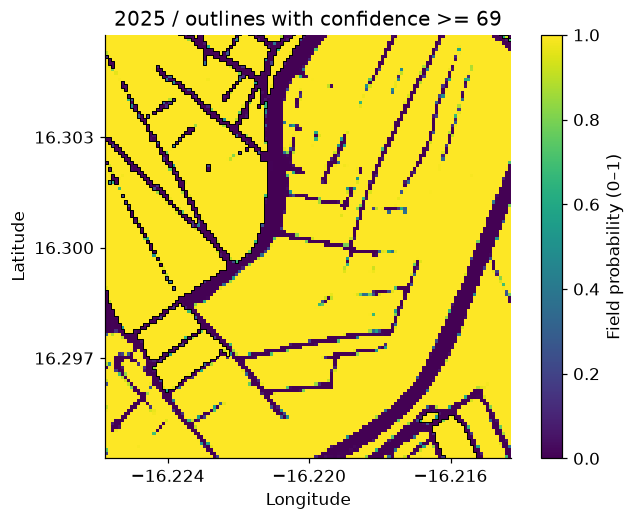

In [4]:
fig,ax=plt.subplots(figsize=(8,4))
for year in d['years']:
    areas=np.array([r[0]/10000 for r in con.execute('SELECT area_m2 FROM fields WHERE year=? AND crosses_window_edge=0 AND area_m2>0',(year,))])
    if len(areas):
        ax.hist(np.log10(areas),bins=12,alpha=.5,label=f'{year}, n={len(areas)}')
ax.set(xlabel='log10(full predicted polygon area / hectares)',ylabel='Polygon count',title='Fully contained predictions / no confidence filter')
ax.legend();plt.show()
fig,ax=plt.subplots(figsize=(7,5))
image=raster_map(ax,d,d['probability'][1,1],'2025 / outlines with confidence >= 69')
fig.colorbar(image,ax=ax,label='Field probability (0–1)')
print('Outlined polygons:',draw_fields(ax,d,2025,69))
plt.show()

## 4. Export a traceable selection to browser GIS

Download the GeoJSON produced below from JupyterLite's file browser and import it into
[GeoLibre Web](https://web.geolibre.app/), or another GeoJSON-capable GIS. Style by `confidence` and inspect
`crosses_window_edge`. The file retains full geometries, the filter, source citation and CC-BY attribution.
It contains no ownership information. External tools have their own availability and terms.

In [5]:
count=export_fields(d,'ftw-selected-fields.geojson',year=2025,min_confidence=69)
print('Exported polygon records:',count)

Exported polygon records: 16


## Try it yourself

Repeat with Kenya. Compare retention at 50, 69 and 90, then write two possible explanations for the difference that do not assume farming quality.

## Check your reasoning

Different imagery, field geometry, training coverage and confidence-model behavior can change retention. A quality filter changes the population being described and needs independent validation.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Global Fields of the World on Source Cooperative](https://source.coop/ftw/global-data), Taylor Geospatial and collaborators, CC-BY-4.0.
- [Robinson et al. (2026), The first global agricultural field boundary map at 10 m resolution](https://doi.org/10.48550/arXiv.2605.11055).
- [Pinned official FTW catalog and product documentation](https://github.com/fieldsoftheworld/ftw-data-catalog/tree/fd844c4c646af0f8e653fba774f79cc17b2af124/catalog). PRUE model predictions use Copernicus Sentinel-2 composites.
- [Exact extracts, source ETags, spatial selection and SHA256 checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ftw-provenance.json). Local modifications: spatial subsets, GeoJSON conversion and scalar Zarr repackaging; original class values and full selected polygon geometries retained.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 24_ftw_fields_confidence')

LESSON COMPLETE: 24_ftw_fields_confidence
